In [1]:
import textwrap

def visualise_texts(texts: list[str], width: int = 100):
    for text in texts:
        print('\n'.join(textwrap.wrap(text, width, break_long_words=False)))
        print('=' * width)
        print('=' * width)

## Analyse chunks from an inquiry

This is done by comparing submission documents to the final recommendations published in the committee report.

In [70]:
from ddd_policy_tracer.analysis.chunks.adapters import SQLiteDocumentChunkRepository
from ddd_policy_tracer.utils.db_manager import DbManager
import pandas as pd

chunk_repository = SQLiteDocumentChunkRepository(db_manager=DbManager.get_instance("data/new2.db"))
chunks = await chunk_repository.list_chunks(source_id="committees")
filtered_chunks = [chunk for chunk in chunks if chunk.topics is not None and chunk.embedding is not None]

df = pd.DataFrame([c.__dict__ for c in filtered_chunks])
df["organisation"] = df["metadata"].apply(lambda x: x.get("doc_metadata", {}).get("submitted_by", None) if x else None)

In [71]:
submission_df = df[df['source_document_id'] != "report_recommendations"]
recommendation_df = df[df['source_document_id'] == "report_recommendations"]

In [72]:
from ddd_policy_tracer.analysis.entities.embedding import EmbeddingService


embedding_service = EmbeddingService()
sims = embedding_service.similarity_many(
    submission_df.embedding.tolist(),
    recommendation_df.embedding.tolist(),
)
submission_df.loc[:, ["sim_1", "sim_2", "sim_3"]] = sims

Loading weights: 100%|██████████| 310/310 [00:00<00:00, 4823.69it/s]


### View chunks similar to the recommendations

In [5]:
print("Recommendation chunk:\n")
visualise_texts([recommendation_df.iloc[2].chunk_text])
print("\nMost similar submission chunks:\n")
visualise_texts(submission_df.sort_values("sim_3", ascending=False).head(3).chunk_text)

Recommendation chunk:

The committee recommends that the Australian Government table a declassified version of the report
prepared by the Office of National Intelligence on the national security threats posed by climate
change in the Australian Parliament within three months.

Most similar submission chunks:

## Transparency and the ONI report   The ALP government is to be commended for commissioning a
climate-and-security risk assessment, authored by ONI. In doing so, it did what every previous
government had failed to do, and which the Liberal and National Parties still refuse to acknowledge
as a necessary task.   Unfortunately, ONI’s report has been securitised, with no declassified
version released, unlike the practice of our major allies, or the practice with the Defence Security
Review.   The report’s key risk conclusions have been buried, such that members of parliament
including those who oversee relevant committees have not seen the ONI report. It is inconceivable
that MPs and

## Most influential docs

In [93]:
import numpy as np
submission_df['embedding'] = submission_df.embedding.apply(np.array)
doc_df = submission_df.groupby("source_document_id").agg({
    "embedding": "sum",
    "organisation": "first",
    "sim_1": "mean",
    "sim_2": "mean",
    "sim_3": "mean",
}).reset_index()

In [97]:
# top 5 documents by average similarity
doc_df['mean_sim'] = doc_df[['sim_1', 'sim_2', 'sim_3']].mean(axis=1)
doc_df.sort_values('mean_sim', ascending=False).head(5)

,source_document_id,embedding,organisation,sim_1,sim_2,sim_3,mean_sim
5,https://www.aph.gov.au/DocumentStore.ashx?id=5...,"[-0.175537109375, 0.151123046875, -0.028747558...","Professor Andrew Pitman AO, FAA",0.627775,0.588984,0.549841,0.588867
6,https://www.aph.gov.au/DocumentStore.ashx?id=5...,"[-0.17724609375, 0.2750101089477539, -0.050292...",Global Shield Australia,0.589665,0.592985,0.555610,0.579420
9,https://www.aph.gov.au/DocumentStore.ashx?id=6...,"[-0.2104339599609375, 0.28912353515625, -0.029...",Australian Climate Service,0.579229,0.572729,0.545121,0.565693
8,https://www.aph.gov.au/DocumentStore.ashx?id=6...,"[-0.13720703125, 0.14794921875, -0.01254272460...",ARC Centre of Excellence for the Weather of th...,0.577528,0.567232,0.544531,0.563097
14,https://www.aph.gov.au/DocumentStore.ashx?id=c...,"[-0.047332763671875, 0.1182861328125, -0.01800...",Department of Finance,0.557393,0.518285,0.555339,0.543672


In [ ]:
# least similar 5 documents
doc_df['mean_sim'] = doc_df[['sim_1', 'sim_2', 'sim_3']].mean(axis=1)
doc_df.sort_values('mean_sim', ascending=True).head(5)

,source_document_id,embedding,organisation,sim_1,sim_2,sim_3,mean_sim
13,https://www.aph.gov.au/DocumentStore.ashx?id=b...,"[-0.037434895833333336, 0.053304036458333336, ...",Mr Bruce Thom,0.388458,0.388502,0.395277,0.390746
2,https://www.aph.gov.au/DocumentStore.ashx?id=2...,"[-0.06453450520833333, 0.109130859375, -0.0030...",National Insurance Brokers Association,0.409295,0.440473,0.354534,0.401434
7,https://www.aph.gov.au/DocumentStore.ashx?id=5...,"[-0.010318756103515625, 0.031227698692908652, ...",Sweltering Cities,0.396380,0.418800,0.403901,0.406360
18,https://www.aph.gov.au/DocumentStore.ashx?id=d...,"[-0.04285394577752976, 0.04723249162946429, -0...",Australian Consumers Insurance Lobby,0.401988,0.439553,0.379292,0.406944
11,https://www.aph.gov.au/DocumentStore.ashx?id=8...,"[-0.020345853722613792, 0.040350209111752716, ...",Housing Industry Association (HIA),0.421158,0.444763,0.388215,0.418046


### See documents in embedding space, find the report_recommendation and see similar documents

<Axes: xlabel='organisation'>

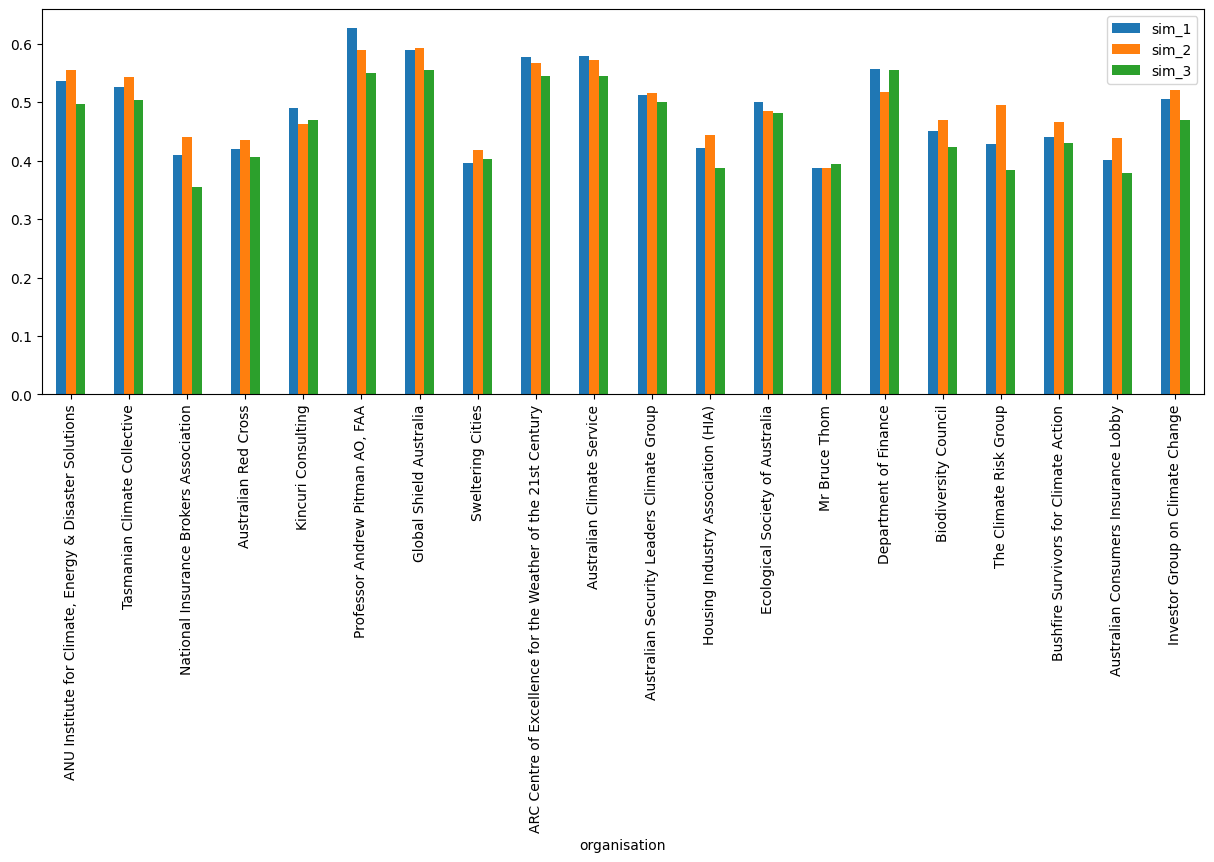

In [98]:
doc_df.loc[:, ['organisation', 'sim_1', 'sim_2', 'sim_3']].plot(x='organisation', kind="bar", layout=(1, 3), figsize=(15, 5))

In [94]:
recommendation_df['organisation'] = "Committee's report recommendations"
merged_df = pd.concat([doc_df.loc[:, ['embedding', 'source_document_id', 'organisation']], recommendation_df.loc[:, ['embedding', 'source_document_id', 'organisation']]], ignore_index=True)

In [95]:
import umap

mapper = umap.UMAP().fit(np.array(merged_df.embedding.tolist()))

In [96]:
import umap.plot

hover_data = pd.DataFrame(
    {
        "index": merged_df.index,
        "document_id": merged_df.source_document_id,
        "label": merged_df.organisation,
    },
)
p = umap.plot.interactive(
    mapper,
    labels=merged_df.organisation.to_list(),
    hover_data=hover_data,
    point_size=5,
    theme="fire",
)
umap.plot.show(p)